# 06 — Temperature profile (quick check for Figure 4)

Tropical-mean (10°S–10°N, cos-latitude weighted) temperature as a function of
longitude and pressure, from the ECHAM6.3 ATM stream (`st`). This notebook is
the interactive check: the climatology, then ΔT = run − climatology for one
event and all three runs, with the climatological temperature contoured on top.
The manuscript figure is made by `10`, which computes the same fields
directly from the model output.

In [1]:
import sys
sys.path.insert(0, "../src")
import config as cfg

import os
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt

RUNS = ["FULL", "UNIFORM", "PATTERN"]


def event_dir(event_type):
    return cfg.ECHAM_OUTPUT_ELNINO_DIR if event_type == "El Niño" else cfg.ECHAM_OUTPUT_LANINA_DIR


def tropical_mean_T(path, period=None):
    """Time-mean, 10S-10N cos-weighted temperature (°C) as (plev, lon)."""
    st = xr.open_dataset(path)["st"]
    if period is not None:
        st = st.sel(time=slice(*period))
    st = st.mean("time") - 273.15
    band = st.sel(lat=slice(-10, 10)) if st.lat[0] < st.lat[-1] else st.sel(lat=slice(10, -10))
    weights = np.cos(np.deg2rad(band.lat))
    return band.weighted(weights).mean("lat")


def show_profile(field, title, cmap="turbo"):
    plt.figure(figsize=(7, 4))
    cf = plt.contourf(field.lon, field.plev / 100, field.values, levels=21, cmap=cmap, extend="both")
    plt.gca().invert_yaxis()
    plt.xlabel("Longitude")
    plt.ylabel("Pressure (hPa)")
    plt.colorbar(cf, label="°C")
    plt.title(title)
    plt.show()


def show_delta_profile(field, clim_field, title, levels, cbar_ticks=None, extend="neither"):
    plt.figure(figsize=(7, 4))
    pcm = plt.contourf(field.lon, field.plev / 100, field.values, levels=levels, cmap="RdBu_r", extend=extend)
    qcs = plt.contour(clim_field.lon, clim_field.plev / 100, clim_field.values, levels=10,
                      colors="black", linewidths=0.8, alpha=0.8)
    plt.gca().invert_yaxis()
    plt.xlabel("Longitude")
    plt.ylabel("Pressure (hPa)")
    plt.colorbar(pcm, label="ΔT (°C)", ticks=cbar_ticks)
    plt.title(f"{title} (contours: climatological T every {qcs.levels[1] - qcs.levels[0]:.0f} °C)")
    plt.show()

## Step 1 — climatology (control run, `cfg.CLIM_PERIOD`)

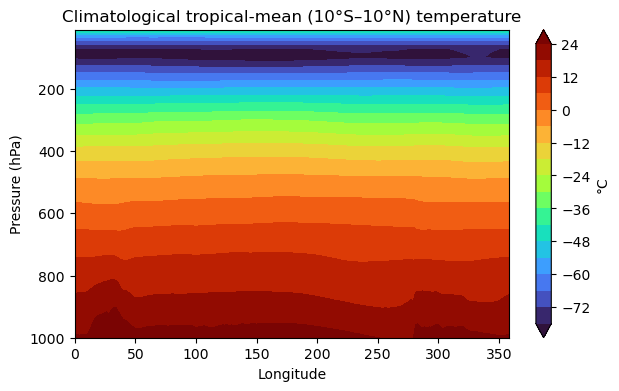

climatology loaded: ('plev', 'lon') (17, 192)


In [2]:
T_clim = tropical_mean_T(cfg.CLIMATOLOGY_ATM_PATH, period=cfg.CLIM_PERIOD)
show_profile(T_clim, "Climatological tropical-mean (10°S–10°N) temperature")
print("climatology loaded:", T_clim.dims, T_clim.shape)

## Step 2 — quick check: ΔT for one event, all three runs

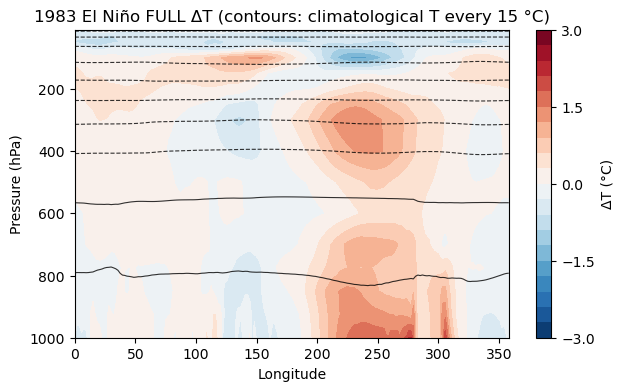

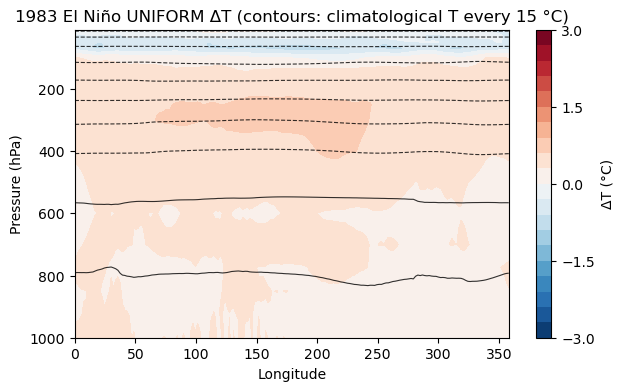

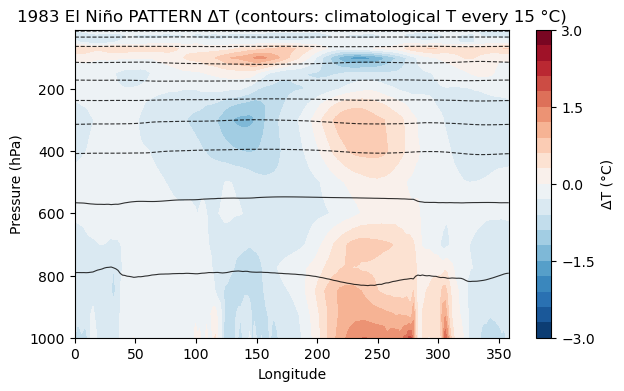

In [3]:
CHECK_EVENT_YEAR = 1983          # <- any event year
CHECK_EVENT_TYPE = "El Niño"     # must match the folder the year's data lives in

VMIN = None       # <- explicit limits in °C, e.g. VMIN = -3, VMAX = 3; None = automatic
VMAX = None
N_LEVELS = 21
TICK_STEP = 1.0   # °C, used to round VMAX up to a clean value
N_TICKS = 5

deltas = {}
for run in RUNS:
    check_path = os.path.join(event_dir(CHECK_EVENT_TYPE), f"{CHECK_EVENT_YEAR}_{run}_echam6_ATM_mm_1976-1999.nc")
    if not os.path.exists(check_path):
        print(f"missing {check_path} -- change CHECK_EVENT_YEAR/CHECK_EVENT_TYPE above")
        continue
    deltas[run] = tropical_mean_T(check_path) - T_clim

if VMAX is None:
    data_vmax = float(max(np.abs(f).max() for f in deltas.values()))
    VMAX = TICK_STEP * np.ceil(data_vmax / TICK_STEP)
if VMIN is None:
    VMIN = -VMAX

levels = np.linspace(VMIN, VMAX, N_LEVELS)
cbar_ticks = np.linspace(VMIN, VMAX, N_TICKS)

for run, field in deltas.items():
    show_delta_profile(field, T_clim, f"{CHECK_EVENT_YEAR} {CHECK_EVENT_TYPE} {run} ΔT", levels, cbar_ticks)